# M02 — Prismas gravimétricos y límite de aceptación inversa

**Level 3 · Prerrequisitos: notebook de fundamentos; lectura: 25 minutos.**

## Objetivos

Ejecute el operador directo SimPEG/Geoana sobre una solicitud sintética explícita de una celda y compare con la función analítica independiente de prisma de Choclo. Falló la puerta nativa conservada de dirección retenida-48; las comprobaciones inversas dependientes están bloqueadas. Este notebook registra ese resultado negativo.

## Preparación

Use el entorno pipeline Python 3.12 ya revisado. Este notebook no instala nada.

Importe el código del repositorio y confirme su archivo fuente.

In [1]:
import sys
from pathlib import Path
import numpy as np
root=Path.cwd().parents[2];sys.path.insert(0,str(root/'data-pipeline'))
import gravity_forward
# Load the product's existing synthetic control, not a field survey.
import choclo
# Fixed one-prism simulation request matching the repository's bounded operator control.
request={"schema":"gravity-prism-forward-request-1","frame":dict(gravity_forward.FRAME),"engine":gravity_forward.ENGINE,
         "mesh":{"origin_m":np.array([-50.,-50.,-100.]),"hx_m":np.array([100.]),"hy_m":np.array([100.]),"hz_m":np.array([100.]),"active":np.array([True])},
         "receivers_m":np.array([[0.,0.,100.],[100.,50.,120.],[-170.,30.,220.]]),"density_kg_m3":np.array([1000.])}
prism_bounds=(-50.,50.,-50.,50.,-100.,0.)
print('Motor gravimétrico:',gravity_forward.ENGINE)

Motor gravimétrico: simpeg-0.25.2-geoana-0.8.1-f64-ram


## Datos

Ejecute el operador directo SimPEG/Geoana sobre una solicitud sintética explícita de una celda y compare con la función analítica independiente de prisma de Choclo. Falló la puerta nativa conservada de dirección retenida-48; las comprobaciones inversas dependientes están bloqueadas. Este notebook registra ese resultado negativo.

**Files:** `data-pipeline/gravity_forward.py`, `docs/design/features/m02-prism-operator/validation.md`.

## Método

Para receptor exterior, la aceleración hacia arriba es g_z=G∫_V Δρ(z′−z)/|r−r′|³ dV. El operador discreto d=Jρ usa contraste kg m⁻³, predicción mGal y J en mGal/(kg m⁻³). Masa positiva enterrada da gz hacia arriba negativo. La inversa agrega errores, referencia, cotas y regularización; los modelos de campos potenciales no son únicos.

Para prisma de densidad constante, g_z(r)=G∫_Vρ(z′−z)/|r−r′|³dV. El producto devuelve g_z hacia arriba en mGal; densidad positiva enterrada predice por tanto un valor negativo sobre el cuerpo. El mapa discreto d=Jρ usa ρ [kg m⁻³], d [mGal] y J [mGal/(kg m⁻³)]. SimPEG/Geoana evalúa la expresión de esquinas del prisma y el oráculo de prueba suma prismas Choclo independientemente. La concordancia solo verifica el operador directo. Una inversa estima ρ desde d≈Jρ con información previa/regularizador; los núcleos amplios de gravedad intercambian profundidad, densidad y extensión lateral, dejando direcciones singulares débiles. Un desajuste bajo por sí solo no resuelve esa ambigüedad.

El código muestrea una transecta horizontal este sobre la solicitud congelada de un prisma. Receptores en z=100 m se simulan explícitamente y quedan fuera de la fuente. Compara predicciones de producto y oráculo independiente punto a punto, con diferencia en un segundo panel. No son datos de campo y no se ajusta densidad. El contrato rechaza receptores sobre o dentro de la malla cerrada; el operador exterior no define allí un límite seguro. El fallo conservado de la puerta nativa retenida-48 sigue bloqueando afirmaciones inversas.


Ejecute el método del producto sobre el control declarado.

In [2]:
# Compare production prediction with Choclo's independent analytic rectangular-prism function.
result=gravity_forward.forward_gravity(request)
oracle=np.array([choclo.prism.gravity_u(*r,*prism_bounds,1000.)*1e5 for r in request['receivers_m']])
print({'prediccion_producto_hacia_arriba_mGal':result['gz_up_mgal'].tolist(),'oraculo_Choclo_mGal':oracle.tolist(),'diferencia_absoluta_maxima_mGal':float(np.max(np.abs(result['gz_up_mgal']-oracle)))})

{'prediccion_producto_hacia_arriba_mGal': [-0.2927236040238318, -0.13493607735120078, -0.05476427211854826], 'oraculo_Choclo_mGal': [-0.29272360402383146, -0.13493607735120078, -0.054764272118546925], 'diferencia_absoluta_maxima_mGal': 1.3322676295501878e-15}


Control adversarial/negativo: aísle un supuesto o incumpla una restricción física declarada.

In [3]:
from copy import deepcopy
invalid=deepcopy(request);invalid['receivers_m']=np.array([[0.0,0.0,-50.0]])
try:
    # Closed-mesh interior receivers violate the forward contract.
    gravity_forward.forward_gravity(invalid)
except ValueError as error:
    print('Rechazo geométrico esperado:',str(error))
else:
    raise AssertionError('Interior receiver was accepted')

Rechazo geométrico esperado: receivers_m: every receiver must be strictly outside closed full source box


## Estado del arte

SimPEG/Geoana es el motor directo de producción ([Cockett et al., 2015](https://doi.org/10.1016/j.cageo.2015.09.015)); la validación del producto utiliza un oráculo analítico independiente de prismas. Concordancia directa no es recuperación de densidad. La inversa sigue no aceptada porque falló dirección retenida-48; las pruebas de nulo positivo y primer pliegue no corrieron.

Ambas curvas son predicciones directas en mGal; el panel inferior es producto menos oráculo independiente, no residual de observación. Una diferencia pequeña entre oráculos no demuestra convergencia inversa ni identificabilidad de densidad.


diferencia absoluta máxima: 7.588e-15 mGal


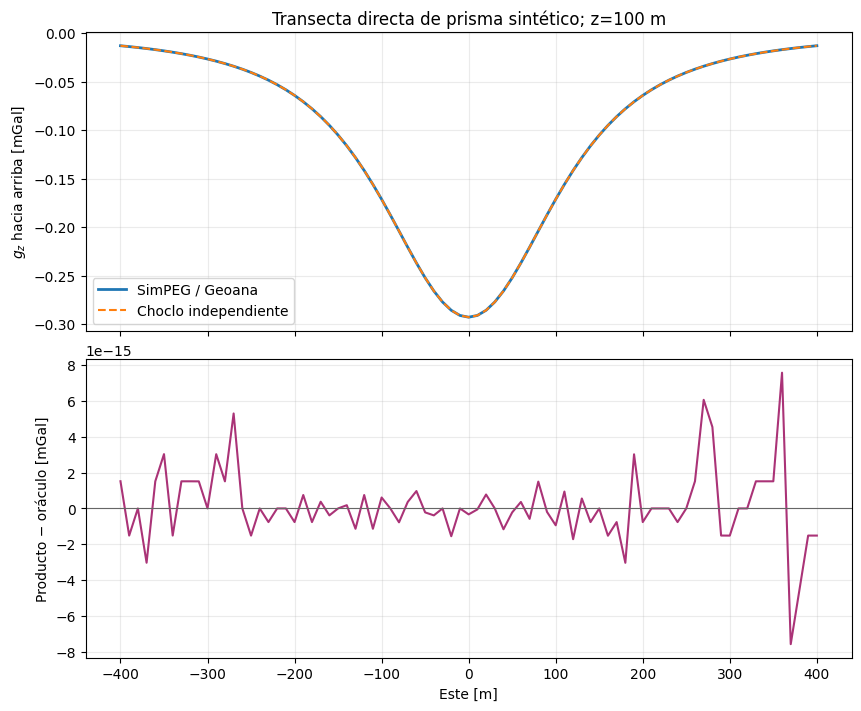

In [4]:
from copy import deepcopy
import matplotlib.pyplot as plt

# Barrer receptores exteriores con el operador de producción y el oráculo independiente de Choclo.
transecta=deepcopy(request); este=np.linspace(-400.,400.,81)
transecta['receivers_m']=np.column_stack([este,np.zeros_like(este),np.full_like(este,100.)])
pred=gravity_forward.forward_gravity(transecta)['gz_up_mgal']; oraculo=np.array([choclo.prism.gravity_u(*r,*prism_bounds,1000.)*1e5 for r in transecta['receivers_m']]); delta=pred-oraculo
fig,(ax,bx)=plt.subplots(2,1,figsize=(8.5,7),sharex=True,constrained_layout=True)
ax.plot(este,pred,label='SimPEG / Geoana',lw=2); ax.plot(este,oraculo,'--',label='Choclo independiente',lw=1.5)
ax.set(ylabel='$g_z$ hacia arriba [mGal]',title='Transecta directa de prisma sintético; z=100 m'); ax.legend(); ax.grid(alpha=.25)
bx.plot(este,delta,color='#aa3377'); bx.axhline(0,color='.4',lw=.8)
bx.set(xlabel='Este [m]',ylabel='Producto − oráculo [mGal]'); bx.grid(alpha=.25)
print(f'diferencia absoluta máxima: {np.max(np.abs(delta)):.3e} mGal')
plt.show()


## Resultados

Solo se evalúa comportamiento directo sintético acotado. El receptor inválido debe rechazarse. No se afirma inversión, ajuste de campo, resultado retenido ni capacidad del host; conserve la puerta fallida ligada al código.

## Resumen

Un núcleo directo validado puede coexistir con una inversa no resuelta. No convierta un fallo conservado del solver en éxito con gráficas o tolerancias cambiadas.




## Referencias

- https://doi.org/10.1016/j.cageo.2015.09.015